In [2]:
import pandas as pd 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

In [9]:
df = pd.read_csv("digits.csv")

In [10]:
df.shape

(1796, 65)

In [11]:
df.head()

,0,0.1,5,13,9,1,0.2,0.3,0.4,0.5,...,0.23,0.24,0.25,6,13.2,10.2,0.26,0.27,0.28,0.29
0,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1
1,0,0,0,4,15,12,0,0,0,0,...,0,0,0,0,3,11,16,9,0,2
2,0,0,7,15,13,1,0,0,0,8,...,0,0,0,7,13,13,9,0,0,3
3,0,0,0,1,11,0,0,0,0,0,...,0,0,0,0,2,16,4,0,0,4
4,0,0,12,10,0,0,0,0,0,0,...,0,0,0,9,16,16,10,0,0,5


In [17]:
print(df.columns.tolist())

['0', '0.1', '5', '13', '9', '1', '0.2', '0.3', '0.4', '0.5', '13.1', '15', '10', '15.1', '5.1', '0.6', '0.7', '3', '15.2', '2', '0.8', '11', '8', '0.9', '0.10', '4', '12', '0.11', '0.12', '8.1', '8.2', '0.13', '0.14', '5.2', '8.3', '0.15', '0.16', '9.1', '8.4', '0.17', '0.18', '4.1', '11.1', '0.19', '1.1', '12.1', '7', '0.20', '0.21', '2.1', '14', '5.3', '10.1', '12.2', '0.22', '0.23', '0.24', '0.25', '6', '13.2', '10.2', '0.26', '0.27', '0.28', '0.29']


In [12]:
print(df.isnull().sum())

0       0
0.1     0
5       0
13      0
9       0
       ..
10.2    0
0.26    0
0.27    0
0.28    0
0.29    0
Length: 65, dtype: int64


In [13]:
df.describe()

,0,0.1,5,13,9,1,0.2,0.3,0.4,0.5,...,0.23,0.24,0.25,6,13.2,10.2,0.26,0.27,0.28,0.29
count,1796.0,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000,...,1796.000000,1796.000000,1796.000000,1796.00000,1796.00000,1796.000000,1796.000000,1796.000000,1796.000000,1796.000000
mean,0.0,0.304009,5.204900,11.835189,11.849666,5.784521,1.363029,0.129733,0.005568,1.994989,...,0.206570,0.000557,0.279510,5.55735,12.08853,11.810134,6.767817,2.069042,0.364699,4.493318
std,0.0,0.907416,4.756148,4.249936,4.288055,5.666871,3.326546,1.037667,0.094248,3.196704,...,0.984663,0.023596,0.934539,5.10443,4.37586,4.935137,5.900105,4.091396,1.860620,2.864140
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.00000,11.00000,10.000000,0.000000,0.000000,0.000000,2.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,4.00000,13.00000,14.000000,6.000000,0.000000,0.000000,4.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,10.00000,16.00000,16.000000,12.000000,2.000000,0.000000,7.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,13.000000,1.000000,9.000000,16.00000,16.00000,16.000000,16.000000,16.000000,16.000000,9.000000


In [21]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [24]:
print("features without PCA :", X_train.shape[1])

features without PCA : 64


In [26]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_before = accuracy_score(y_test, knn.predict(X_test))
print("Accuracy before PCA :", round(acc_before, 4))

Accuracy before PCA : 0.9778


In [27]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Features before PCA :", X_train.shape[1])
print("Features after PCA :", X_train_pca.shape[1])

Features before PCA : 64
Features after PCA : 40


In [30]:
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_pca, y_train)
acc_after = accuracy_score(y_test, knn2.predict(X_test_pca))
print("Accuracy after PCA :", round(acc_after, 4))

Accuracy after PCA : 0.9806


In [31]:
result = pd.DataFrame({
    "" : ["Before PCA", "After PCA"],
    "Features" : [X_train.shape[1], X_train_pca.shape[1]],
    "KNN Accuracy" : [acc_before, acc_after]
})

print(result.round(4))

               Features  KNN Accuracy
0  Before PCA        64        0.9778
1   After PCA        40        0.9806


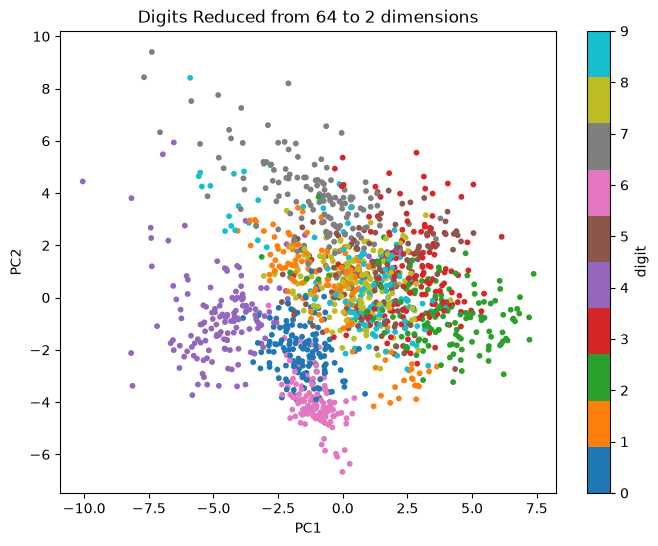

Variance kept by 2 components : 0.217


In [32]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_train)
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="tab10", s=10)
plt.colorbar(label="digit")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digits Reduced from 64 to 2 dimensions")
plt.show()

print("Variance kept by 2 components :", round(pca2.explained_variance_ratio_.sum(), 3))

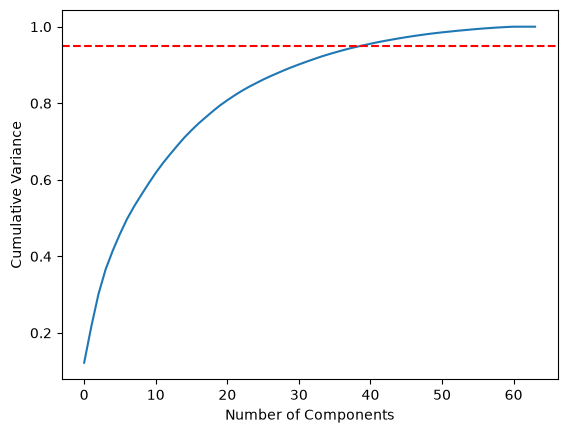

In [33]:
full = PCA().fit(X_train)
plt.plot(full.explained_variance_ratio_.cumsum())
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.show()